In [3]:
import anndata as ad
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import os

In [ ]:
adata = ad.read_h5ad("/work/magroup/skrieger/Syndri/data/datasets/allenbrain_merfish/raw/spatial/c93d78c2-ee17-4504-8d1c-17cf093ad7b5.h5ad")


AnnData object with n_obs × n_vars = 378918 × 374
    obs: 'fov', 'center_x', 'center_y', 'min_x', 'max_x', 'min_y', 'max_y', 'age', 'clust_annot', 'slice', 'sex_ontology_term_id', 'suspension_type', 'cell_type_ontology_term_id', 'assay_ontology_term_id', 'tissue_ontology_term_id', 'disease_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'development_stage_ontology_term_id', 'donor_id', 'is_primary_data', 'cell_type_annot', 'tissue_type', 'cell_type', 'assay', 'disease', 'sex', 'tissue', 'self_reported_ethnicity', 'development_stage', 'observation_joinid'
    var: 'feature_is_filtered', 'feature_name', 'feature_reference', 'feature_biotype', 'feature_length', 'feature_type'
    uns: 'batch_condition', 'citation', 'is_pre_analysis', 'organism', 'organism_ontology_term_id', 'schema_reference', 'schema_version', 'title'
    obsm: 'X_pca', 'X_spatial_coords', 'X_umap', 'spatial_coords'

In [8]:
adata = adata[adata.obs.sample(frac=1.0).index]
adata = adata[adata.obs.groupby('cell_type').head(n=10000).index]
adata

/tmp/ipykernel_1592247/438048326.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  adata = adata[adata.obs.groupby('cell_type').head(n=10000).index]


View of AnnData object with n_obs × n_vars = 94833 × 374
    obs: 'fov', 'center_x', 'center_y', 'min_x', 'max_x', 'min_y', 'max_y', 'age', 'clust_annot', 'slice', 'sex_ontology_term_id', 'suspension_type', 'cell_type_ontology_term_id', 'assay_ontology_term_id', 'tissue_ontology_term_id', 'disease_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'development_stage_ontology_term_id', 'donor_id', 'is_primary_data', 'cell_type_annot', 'tissue_type', 'cell_type', 'assay', 'disease', 'sex', 'tissue', 'self_reported_ethnicity', 'development_stage', 'observation_joinid'
    var: 'feature_is_filtered', 'feature_name', 'feature_reference', 'feature_biotype', 'feature_length', 'feature_type'
    uns: 'batch_condition', 'citation', 'is_pre_analysis', 'organism', 'organism_ontology_term_id', 'schema_reference', 'schema_version', 'title'
    obsm: 'X_pca', 'X_spatial_coords', 'X_umap', 'spatial_coords'

In [9]:
from sklearn.decomposition import PCA
from umap import UMAP

X = adata.X.copy()

X = (X-np.mean(X,axis=0))/(np.std(X,axis=0)+np.finfo(float).eps)

X_pca = PCA(n_components=30).fit_transform(X)

X_umap = UMAP(n_components=2).fit_transform(X_pca)

adata.obsm['X_umap_spatialonly'] = X_umap

/tmp/ipykernel_1592247/3704787410.py:12: ImplicitModificationWarning: Setting element `.obsm['X_umap_spatialonly']` of view, initializing view as actual.
  adata.obsm['X_umap_spatialonly'] = X_umap


In [ ]:
fig,ax = plt.subplots(figsize=(7,5),dpi=200)
ax = sns.scatterplot(x=adata.obs['center_x'],y=adata.obs['center_y'],hue=adata.obs['cell_type'],s=1,ax=ax)
# ax = sns.scatterplot(x=adata.obsm['X_umap'][:,0],y=adata.obsm['X_umap'][:,1],hue=adata.obs['cell_type'],s=1)
ax.legend(bbox_to_anchor=(1,1.05),markerscale=6)
ax.set_title('MERFISH')

KeyboardInterrupt: 

Text(0.5, 1.0, 'MERFISH')

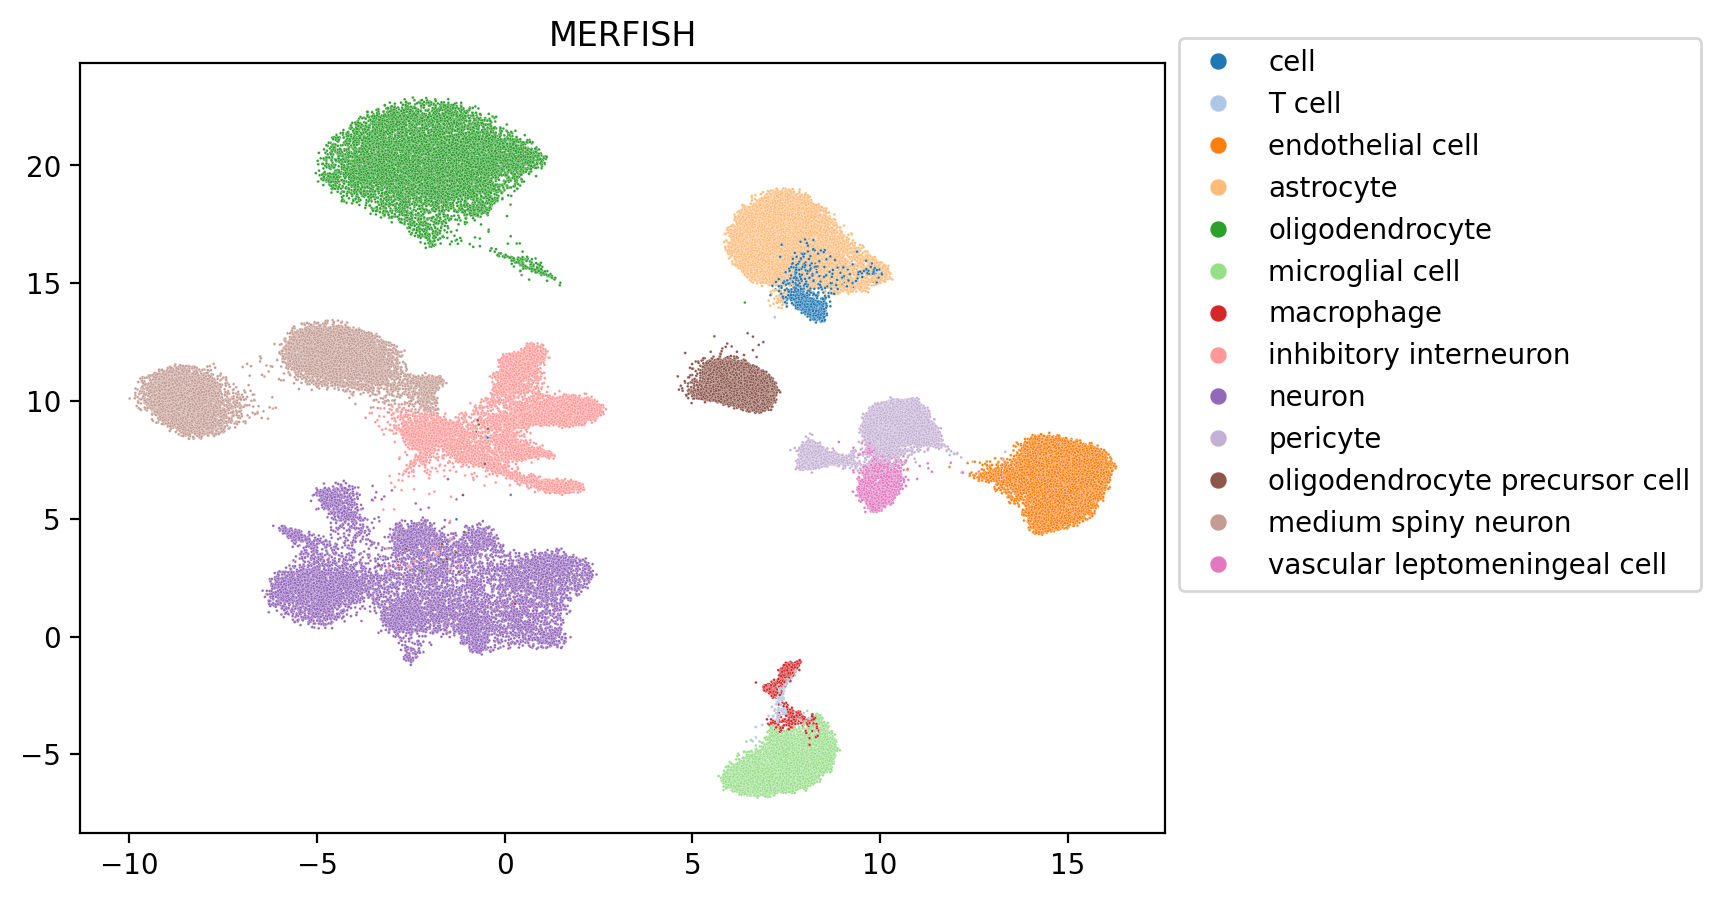

In [16]:
fig,ax = plt.subplots(figsize=(7,5),dpi=200)
# ax = sns.scatterplot(x=adata.obsm['X_umap_spatialonly'][:,0],y=adata.obsm['X_umap_spatialonly'][:,1],hue=adata.obs['cell_type'],s=1,ax=ax,palette='tab20')
ax = sns.scatterplot(x=adata.obsm['X_umap'][:,0],y=adata.obsm['X_umap'][:,1],hue=adata.obs['cell_type'],s=1,palette='tab20')
ax.legend(bbox_to_anchor=(1,1.05),markerscale=6)
ax.set_title('MERFISH')

In [18]:
adata = ad.read_h5ad("/work/magroup/skrieger/Syndri/data/datasets/allenbrain_merfish/raw/single-cell/752ed29d-bbb0-45bd-9c57-19edf68ef73e.h5ad")

adata

AnnData object with n_obs × n_vars = 79667 × 20929
    obs: 'age', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'n_genes', 'n_counts', 'clust_annot', 'sex_ontology_term_id', 'suspension_type', 'cell_type_ontology_term_id', 'assay_ontology_term_id', 'tissue_ontology_term_id', 'disease_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'development_stage_ontology_term_id', 'donor_id', 'is_primary_data', 'cell_type_annot', 'tissue_type', 'cell_type', 'assay', 'disease', 'sex', 'tissue', 'self_reported_ethnicity', 'development_stage', 'observation_joinid'
    var: 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'feature_is_filtered', 'mean', 'std', 'feature_name', 'feature_reference', 'feature_biotype', 'feature_length', 'feature_type'
    uns: 'age_colors', 'batch_condition', 'citation', 'is_pre_analysis', 'leiden', 'neighbors', 'organism', 'organism_ontology_term_id', 'pca', 'schema_reference', 'schema_version', 'title', 'umap'
    obsm: '

Text(0.5, 1.0, 'scRNA-seq')

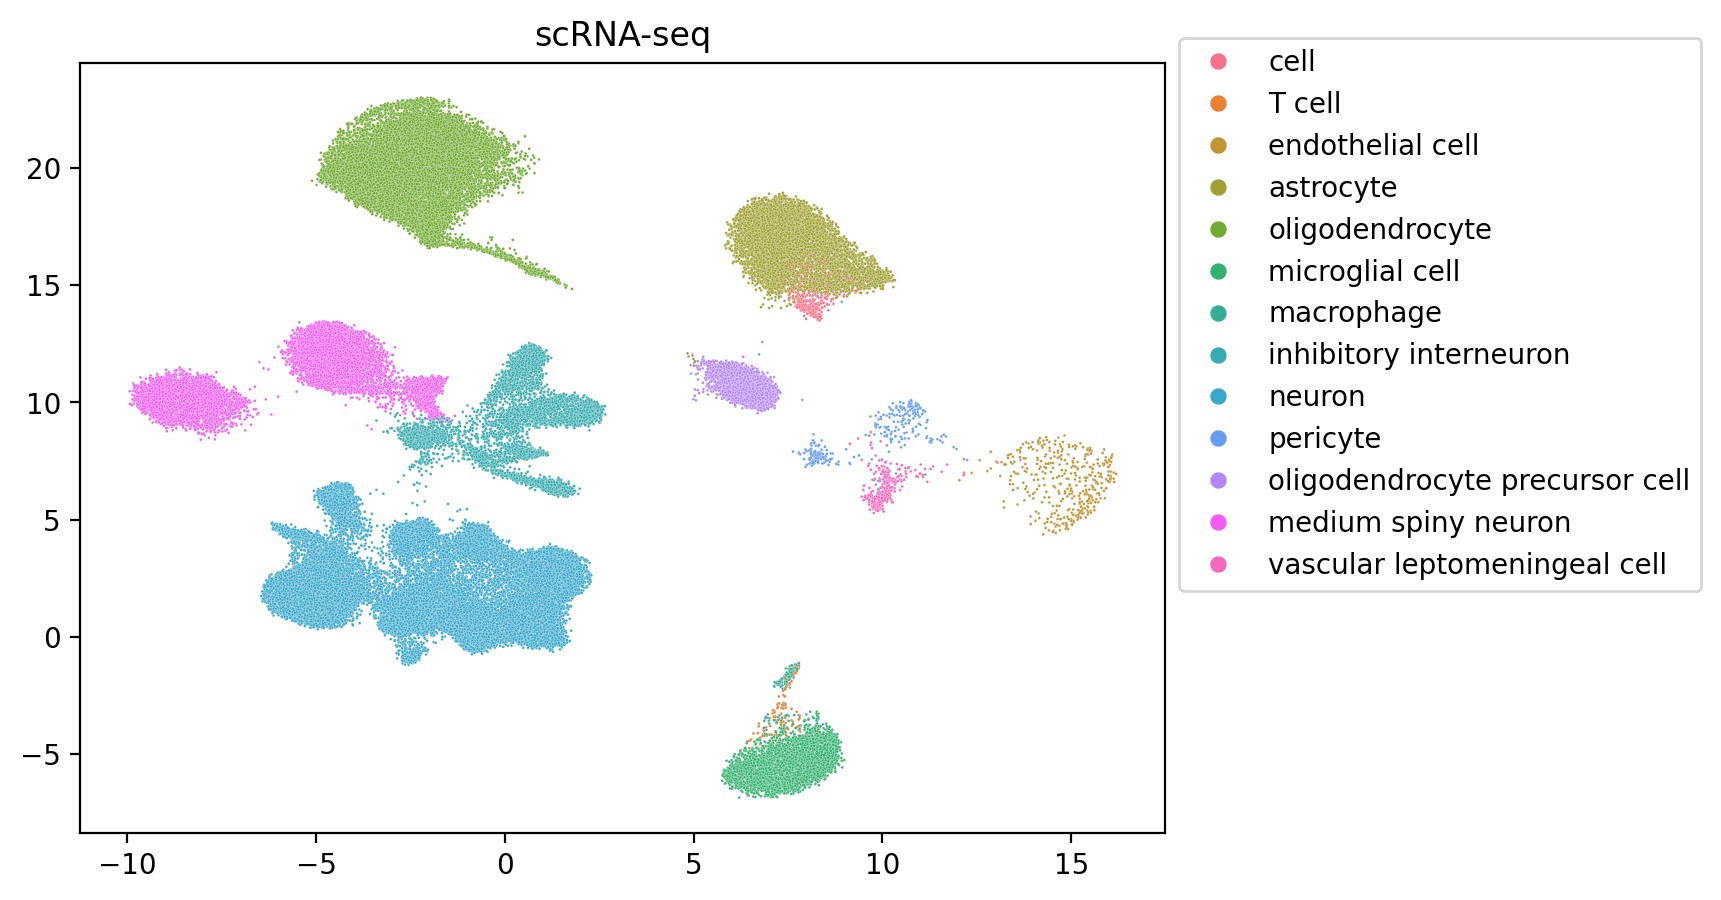

In [19]:
fig,ax = plt.subplots(figsize=(7,5),dpi=200)
ax = sns.scatterplot(x=adata.obsm['X_umap'][:,0],y=adata.obsm['X_umap'][:,1],hue=adata.obs['cell_type'],s=1,ax=ax)
# ax = sns.scatterplot(x=adata.obsm['X_umap'][:,0],y=adata.obsm['X_umap'][:,1],hue=adata.obs['cell_type'],s=1)
ax.legend(bbox_to_anchor=(1,1.05),markerscale=6)
ax.set_title("scRNA-seq")